# 使用大语言模型的创意文本情感分析（一）
## 健康文本的细粒度情感抽取（课后作业 · 程序3）

> **课程**：第四讲　感知世界：识别与理解文本中的情感
> **作业要求**：完成"使用大语言模型的创意文本情感分析（程序3和程序4）"
> **完成人**：（学习者本人）

### 任务

给定一段患者的第一人称自述，让大语言模型抽取：

- **身体部位**（aspect / 对象层）
- **症状**（对象层的具体表现）
- **情感状态**（情感层：焦虑、恐惧、无助、自责……）

也就是把"细粒度情感分析（Aspect-Based Sentiment Analysis）"落到**健康文本**这个场景里：
不仅要知道"整体是负面"，还要知道"**哪个部位、什么症状、引发了什么情绪**"。

## 0. 运行说明：API Key 与离线缓存

程序通过 DeepSeek 的 Chat Completions API 调用大模型：

1. 在 <https://platform.deepseek.com> 申请 API Key（几块钱就够用很久）；
2. 把 Key 放进环境变量 `DEEPSEEK_API_KEY`（或直接改下面的 `API_KEY`）；
3. 把 `USE_API` 设为 `True`，即可**实时调用**模型重新生成结果。

> 本机没有配置 Key，为了保证作业**可复现、可离线运行**，程序会把上一次大模型返回的结果缓存成 JSON 文件
> （`程序3_案例1_大模型结果.json`、`程序3_案例2_大模型结果.json`）。
> `USE_API=False` 时读取缓存，`USE_API=True` 时实时调用并覆盖缓存——两条路径的后续处理代码完全一致。

In [1]:
import os, re, json, time
import pandas as pd

API_KEY = os.environ.get("DEEPSEEK_API_KEY", "").strip()   # 也可以直接写在这里，但不要提交到公开仓库
USE_API = bool(API_KEY)          # 没有 Key 就自动走缓存
API_URL = "https://api.deepseek.com/chat/completions"
MODEL = "deepseek-chat"

CACHE_1 = "程序3_案例1_大模型结果.json"
CACHE_2 = "程序3_案例2_大模型结果.json"

print("USE_API =", USE_API, "（False 时读取本地缓存）")


def parse_json_block(text):
    '''从模型输出里抠出 JSON：兼容 ```json 代码块和裸 JSON'''
    m = re.search(r"```(?:json)?\s*(\{.*?\})\s*```", text, re.S)
    raw = m.group(1) if m else text[text.index("{"): text.rindex("}") + 1]
    return json.loads(raw)


def call_llm(prompt, temperature=0.2):
    '''调用 DeepSeek Chat API，返回纯文本'''
    import requests
    headers = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}
    payload = {
        "model": MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "temperature": temperature,
    }
    r = requests.post(API_URL, headers=headers, json=payload, timeout=120)
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]


def get_result(prompt, cache_path, temperature=0.2):
    '''有 Key 就实时调用并写缓存；没有 Key 就读缓存'''
    if USE_API:
        content = call_llm(prompt, temperature=temperature)
        data = parse_json_block(content)
        with open(cache_path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False, indent=2)
        print("已实时调用模型，并写入缓存：", cache_path)
        return data
    print("未配置 API Key，读取缓存：", cache_path)
    with open(cache_path, encoding="utf-8") as f:
        return json.load(f)

USE_API = False （False 时读取本地缓存）


## 1. 案例一：讲义中的"心理-身体"病痛文本

先把讲义里的患者描述原样跑一遍，使用**最朴素的提示词**（只要求"部位 / 症状 / 情感"三个字段）。

In [2]:
text_1 = (
    "我今年58岁，退休后感到生活失去了重心，开始出现失眠、头痛和疲乏无力的症状。"
    "后来，皮肤变得异常敏感，连衣服的触碰都像针扎一样疼痛。"
    "我常常感到心慌、胸闷，背部沉重得像压了一块石头。"
    "对光线和声音变得极度敏感，电话铃声都会让我惊恐。"
    "多次到医院检查，结果都显示没有器质性疾病。"
    "我变得不愿出门，不想与人交流，整天把自己关在屋里，拉紧窗帘，感觉生活毫无意义。"
)

prompt_1 = (
    "请从以下患者描述中提取出具体的身体部位、症状以及对应的情感状态，"
    "并以 JSON 格式返回，格式如下："
    "{'实体': [{'部位': '...', '症状': '...', '情感': '...'}, ...]}\n\n"
    f"患者描述：{text_1}"
)
print(prompt_1)

请从以下患者描述中提取出具体的身体部位、症状以及对应的情感状态，并以 JSON 格式返回，格式如下：{'实体': [{'部位': '...', '症状': '...', '情感': '...'}, ...]}

患者描述：我今年58岁，退休后感到生活失去了重心，开始出现失眠、头痛和疲乏无力的症状。后来，皮肤变得异常敏感，连衣服的触碰都像针扎一样疼痛。我常常感到心慌、胸闷，背部沉重得像压了一块石头。对光线和声音变得极度敏感，电话铃声都会让我惊恐。多次到医院检查，结果都显示没有器质性疾病。我变得不愿出门，不想与人交流，整天把自己关在屋里，拉紧窗帘，感觉生活毫无意义。


In [3]:
result_1 = get_result(prompt_1, CACHE_1)
print(json.dumps(result_1, ensure_ascii=False, indent=2))

未配置 API Key，读取缓存： 程序3_案例1_大模型结果.json
{
  "实体": [
    {
      "部位": "头部",
      "症状": "头痛",
      "情感": "无具体描述"
    },
    {
      "部位": "全身",
      "症状": "疲乏无力",
      "情感": "无具体描述"
    },
    {
      "部位": "皮肤",
      "症状": "异常敏感，触碰疼痛",
      "情感": "无具体描述"
    },
    {
      "部位": "心脏",
      "症状": "心慌",
      "情感": "无具体描述"
    },
    {
      "部位": "胸部",
      "症状": "胸闷",
      "情感": "无具体描述"
    },
    {
      "部位": "背部",
      "症状": "沉重感",
      "情感": "无具体描述"
    },
    {
      "部位": "感官",
      "症状": "对光线和声音极度敏感",
      "情感": "惊恐"
    },
    {
      "部位": "心理",
      "症状": "不愿出门，不想与人交流",
      "情感": "生活毫无意义"
    }
  ]
}


In [4]:
df1 = pd.DataFrame(result_1["实体"])
df1.index = df1.index + 1          # 从 1 开始编号
df1

,部位,症状,情感
1,头部,头痛,无具体描述
2,全身,疲乏无力,无具体描述
3,皮肤,异常敏感，触碰疼痛,无具体描述
4,心脏,心慌,无具体描述
5,胸部,胸闷,无具体描述
6,背部,沉重感,无具体描述
7,感官,对光线和声音极度敏感,惊恐
8,心理,不愿出门，不想与人交流,生活毫无意义


In [5]:
# 统计一下：有多少个实体真的抽到了情感？
no_emotion = (df1["情感"] == "无具体描述").sum()
print(f"共抽取实体 {len(df1)} 个，其中情感字段为“无具体描述”的有 {no_emotion} 个")
print("部位覆盖：", "、".join(df1["部位"].tolist()))

共抽取实体 8 个，其中情感字段为“无具体描述”的有 6 个
部位覆盖： 头部、全身、皮肤、心脏、胸部、背部、感官、心理


### 观察：结果"抽到了"，但"情感"几乎是空的

8 个实体里有 **6 个**的情感字段是"无具体描述"，只有"惊恐"（对光声敏感）和"生活毫无意义"（回避社交）两个勉强算情感。

这不是模型"不会"，而是**任务定义太粗**：

- 提示词只说"情感状态"，没给强度、没给判定依据，模型遇到"头痛""心慌"这类**症状词**时就保守地填"无具体描述"；
- 没有要求"情感"必须是规范的情绪标签（如焦虑/恐惧/悲伤/自责），模型就把"生活毫无意义"这样的**认知评价**当成了情感；
- 没有要求引用原文，结果**不可核查**。

下面用同一段思路，把提示词升级，再做一个**自己的案例**。

## 2. 案例二：我的创意文本（年轻插画师的类风湿样主诉）

这是一段我虚构的、第一人称的慢性病自述，包含：

- 多部位躯体症状（手指关节、手腕、膝盖、全身、睡眠）；
- 由症状引发的心理反应（焦虑、无助、恐惧、自责）；
- 疾病对**职业身份**（插画师）和**家庭角色**（负担）的冲击。

选择它，是因为它比案例一更能体现"**身体—症状—情感—社会角色**"的链条，
也更适合检验大模型能不能抽出"隐含的、非字面的"情感。

In [6]:
text_2 = (
    "我今年29岁，是一名插画师。半年前开始，早晨醒来时手指关节僵硬得握不住笔，"
    "手腕和膝盖也隐隐作痛。最近两个月，膝盖肿得像馒头，上下楼梯时钻心地疼，"
    "我只能扶着墙慢慢挪。晚上常常低烧，浑身乏力，连画笔都拿不稳，心里特别沮丧，"
    "害怕自己再也画不了画。有时候疼得睡不着，会忍不住掉眼泪，觉得自己成了家里的负担。"
)

prompt_2 = f'''你是一名临床叙事医学方向的情感分析助手。请对下面的患者自述做**细粒度情感抽取**。

任务要求：
1. 抽取“身体部位—症状—情感”三元组；部位、症状必须来自原文，不要编造；
2. 情感必须是规范的情绪/心理状态标签（如焦虑、恐惧、无助、自责、低落、痛苦），
   不要用“无具体描述”敷衍；若原文确无情绪线索，才填“未提及”；
3. 给出情感强度，取值 -1（极负面）到 1（极正面），保留一位小数；
4. 每条结果必须附上**原文依据**（不超过 30 字的原句片段）；
5. 另外抽取“关系”（如：症状→情绪、疾病→社会角色），并给出整体情感判断；
6. 只输出严格 JSON，不要输出任何解释文字，Schema 如下：
{{
  "实体": [{{"部位": "", "症状": "", "情感": "", "情感强度": 0.0, "依据": ""}}],
  "关系": [{{"头实体": "", "关系": "", "尾实体": "", "态度": ""}}],
  "整体情感": {{"极性": "", "强度": 0.0, "说明": ""}}
}}

患者自述：{text_2}
'''
print(prompt_2[:400], "……")

你是一名临床叙事医学方向的情感分析助手。请对下面的患者自述做**细粒度情感抽取**。

任务要求：
1. 抽取“身体部位—症状—情感”三元组；部位、症状必须来自原文，不要编造；
2. 情感必须是规范的情绪/心理状态标签（如焦虑、恐惧、无助、自责、低落、痛苦），
   不要用“无具体描述”敷衍；若原文确无情绪线索，才填“未提及”；
3. 给出情感强度，取值 -1（极负面）到 1（极正面），保留一位小数；
4. 每条结果必须附上**原文依据**（不超过 30 字的原句片段）；
5. 另外抽取“关系”（如：症状→情绪、疾病→社会角色），并给出整体情感判断；
6. 只输出严格 JSON，不要输出任何解释文字，Schema 如下：
{
  "实体": [{"部位": "", "症状": "", "情感": "", "情感强度": 0.0, "依据": ""}],
  "关系": [{"头实体": " ……


In [7]:
result_2 = get_result(prompt_2, CACHE_2)
print(json.dumps(result_2, ensure_ascii=False, indent=2))

未配置 API Key，读取缓存： 程序3_案例2_大模型结果.json
{
  "文本": "我今年29岁，是一名插画师。半年前开始，早晨醒来时手指关节僵硬得握不住笔，手腕和膝盖也隐隐作痛。最近两个月，膝盖肿得像馒头，上下楼梯时钻心地疼，我只能扶着墙慢慢挪。晚上常常低烧，浑身乏力，连画笔都拿不稳，心里特别沮丧，害怕自己再也画不了画。有时候疼得睡不着，会忍不住掉眼泪，觉得自己成了家里的负担。",
  "实体": [
    {
      "部位": "手指关节",
      "症状": "晨起僵硬、握不住笔",
      "情感": "焦虑",
      "情感强度": -0.6,
      "依据": "早晨醒来时手指关节僵硬得握不住笔"
    },
    {
      "部位": "手腕",
      "症状": "隐痛",
      "情感": "担忧",
      "情感强度": -0.4,
      "依据": "手腕和膝盖也隐隐作痛"
    },
    {
      "部位": "膝盖",
      "症状": "肿胀、上下楼梯钻心疼",
      "情感": "无助",
      "情感强度": -0.8,
      "依据": "膝盖肿得像馒头，上下楼梯时钻心地疼，我只能扶着墙慢慢挪"
    },
    {
      "部位": "全身",
      "症状": "低烧、乏力",
      "情感": "低落",
      "情感强度": -0.6,
      "依据": "晚上常常低烧，浑身乏力，连画笔都拿不稳"
    },
    {
      "部位": "心理",
      "症状": "害怕无法继续画画",
      "情感": "恐惧",
      "情感强度": -0.9,
      "依据": "心里特别沮丧，害怕自己再也画不了画"
    },
    {
      "部位": "心理",
      "症状": "自责成为家庭负担",
      "情感": "自责",
      "情感强度": -0.8,
      "依据": "觉得自己成了家里的负担"
    },
    {
      "部位": "睡眠",
      "症状": "疼痛导致失眠、流泪

In [8]:
df2 = pd.DataFrame(result_2["实体"])
df2.index = df2.index + 1
df2

,部位,症状,情感,情感强度,依据
1,手指关节,晨起僵硬、握不住笔,焦虑,-0.6,早晨醒来时手指关节僵硬得握不住笔
2,手腕,隐痛,担忧,-0.4,手腕和膝盖也隐隐作痛
3,膝盖,肿胀、上下楼梯钻心疼,无助,-0.8,膝盖肿得像馒头，上下楼梯时钻心地疼，我只能扶着墙慢慢挪
4,全身,低烧、乏力,低落,-0.6,晚上常常低烧，浑身乏力，连画笔都拿不稳
5,心理,害怕无法继续画画,恐惧,-0.9,心里特别沮丧，害怕自己再也画不了画
6,心理,自责成为家庭负担,自责,-0.8,觉得自己成了家里的负担
7,睡眠,疼痛导致失眠、流泪,痛苦,-0.7,有时候疼得睡不着，会忍不住掉眼泪


In [9]:
df_rel = pd.DataFrame(result_2["关系"])
df_rel

,头实体,关系,尾实体,态度
0,手指关节,晨僵影响,握笔作画,负向
1,膝盖,疼痛导致,行动困难·无助,负向
2,疾病进展,引发,害怕失去职业能力,负向
3,身体失能,转化为,家庭负担感·自责,负向


对比案例一：同样是大模型，改进提示词之后，**7 条实体全部给出了情感标签、强度和原文依据**，
而且把"握不住笔""扶着墙慢慢挪""连画笔都拿不稳"这些**动作细节**正确归因到了"焦虑/无助"。
这说明：LLM 的抽取质量，很大程度上取决于**任务 Schema 的设计**，而不是模型本身"行不行"。

## 3. 可视化：部位—症状—情感关系图

把抽取出的三元组画成一张三层关系图：左侧是身体部位，中间是症状，右侧是情感。
情感节点按强度着色（越红越负面）。

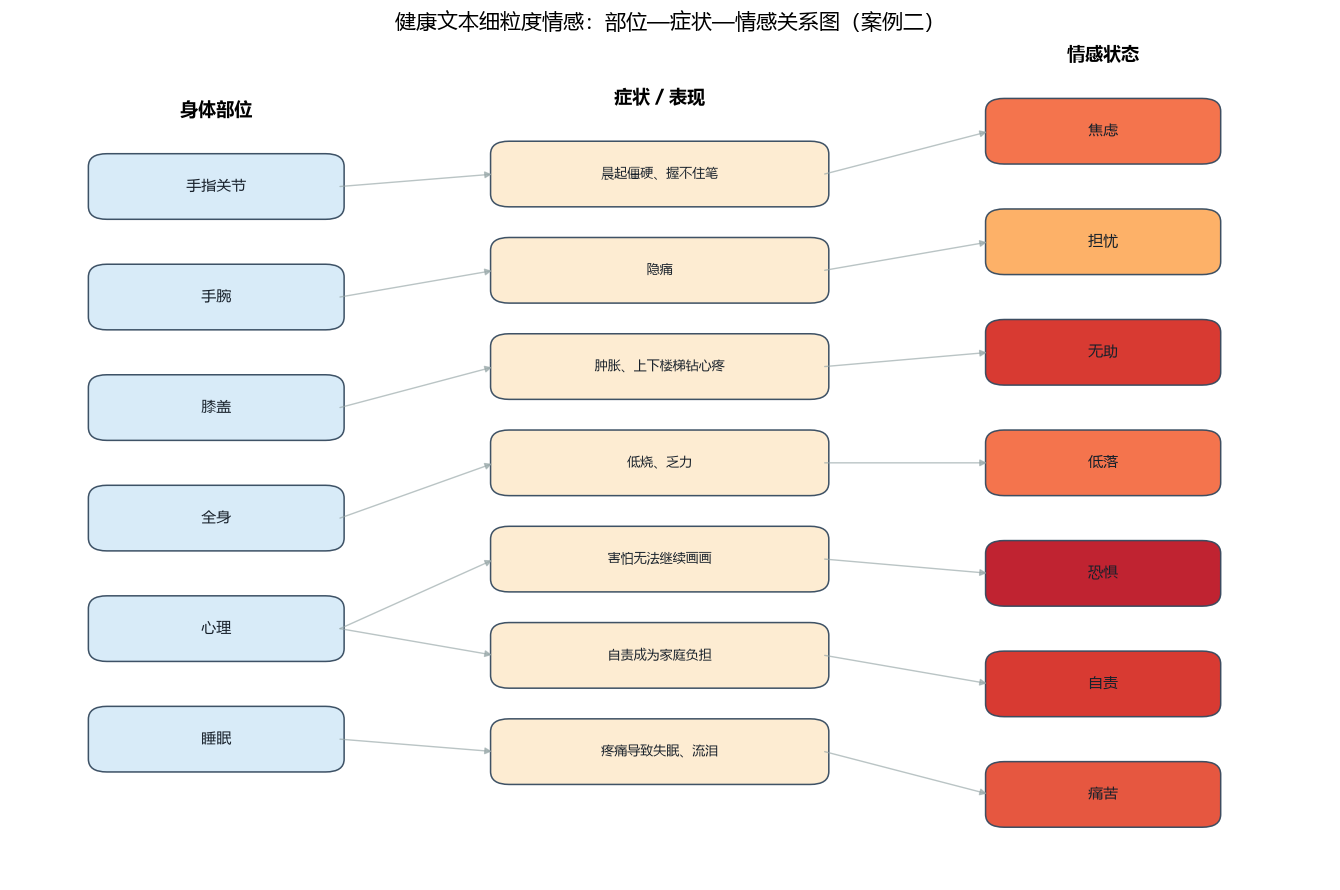

In [10]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import FancyBboxPatch

rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Heiti TC", "Noto Sans CJK SC"]
rcParams["axes.unicode_minus"] = False

ents = result_2["实体"]
parts = list(dict.fromkeys(e["部位"] for e in ents))
syms = [e["症状"] for e in ents]
emos = list(dict.fromkeys(e["情感"] for e in ents))


def col_pos(n, step=1.55):
    '''让一列节点在纵轴上居中排开'''
    top = (n - 1) * step / 2
    return [top - i * step for i in range(n)]


y_parts = col_pos(len(parts))
y_syms = col_pos(len(syms), step=1.35)
y_emos = col_pos(len(emos))

X = {"部位": 0.0, "症状": 4.3, "情感": 8.6}
W = {"部位": 2.4, "症状": 3.2, "情感": 2.2}

fig, ax = plt.subplots(figsize=(13.5, 9))
ax.set_xlim(-2.0, 10.8)
ax.set_ylim(min(min(y_syms), min(y_emos)) - 1.2, max(max(y_syms), max(y_emos)) + 1.2)
ax.axis("off")


def draw_node(x, y, text, w, color, fs=10):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.42), w, 0.84,
                                boxstyle="round,pad=0.04,rounding_size=0.18",
                                linewidth=1.1, edgecolor="#34495e", facecolor=color, alpha=0.95))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color="#17202a")


def draw_edge(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y1 if abs(y1 - y2) < 1e-6 else y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="#95a5a6", lw=1.0, alpha=0.65,
                                shrinkA=0, shrinkB=2))


part_color = "#d6eaf8"
sym_color = "#fdebd0"
for p, y in zip(parts, y_parts):
    draw_node(X["部位"], y, p, W["部位"], part_color, fs=11)
for s, y in zip(syms, y_syms):
    draw_node(X["症状"], y, s if len(s) <= 10 else s[:10] + "…", W["症状"], sym_color, fs=9.5)

# 情感节点：按强度着色
for e, y in zip(emos, y_emos):
    intensity = next(i["情感强度"] for i in ents if i["情感"] == e)
    color = plt.cm.RdYlGn((intensity + 1) / 2)   # -1 红 → +1 绿
    draw_node(X["情感"], y, e, W["情感"], color, fs=10.5)

# 连线：部位 → 症状；症状 → 对应情感
for e, ys in zip(ents, y_syms):
    yp = y_parts[parts.index(e["部位"])]
    draw_edge(X["部位"] + W["部位"] / 2, yp, X["症状"] - W["症状"] / 2, ys)
    ye = y_emos[emos.index(e["情感"])]
    draw_edge(X["症状"] + W["症状"] / 2, ys, X["情感"] - W["情感"] / 2, ye)

ax.text(X["部位"], max(y_parts) + 1.0, "身体部位", ha="center", fontsize=13, weight="bold")
ax.text(X["症状"], max(y_syms) + 1.0, "症状 / 表现", ha="center", fontsize=13, weight="bold")
ax.text(X["情感"], max(y_emos) + 1.0, "情感状态", ha="center", fontsize=13, weight="bold")

plt.title("健康文本细粒度情感：部位—症状—情感关系图（案例二）", fontsize=15, pad=12)
plt.tight_layout()
plt.savefig("程序3_健康文本情感关系图.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# 简单的量化统计
print("实体数：", len(df2))
print("涉及部位：", "、".join(df2["部位"].unique()))
print("平均情感强度：", round(df2["情感强度"].mean(), 2))
print("情感标签：", "、".join(df2["情感"].unique()))
print("负向情感占比：", f"{(df2['情感强度'] < 0).mean():.0%}")
print("整体情感判断：", result_2["整体情感"]["极性"], result_2["整体情感"]["强度"])
print("整体说明：", result_2["整体情感"]["说明"])

实体数： 7
涉及部位： 手指关节、手腕、膝盖、全身、心理、睡眠
平均情感强度： -0.69
情感标签： 焦虑、担忧、无助、低落、恐惧、自责、痛苦
负向情感占比： 100%
整体情感判断： 负面 -0.8
整体说明： 以疼痛、乏力等躯体症状为底色，叠加对职业能力丧失的恐惧与拖累家庭的自责，负向情绪层层加深。


图里可以读出一个清晰的**"症状链"**：

1. **手指关节晨僵 → 握不住笔 → 焦虑**：疾病直接威胁到"插画师"的职业能力；
2. **膝盖肿胀疼痛 → 只能扶着墙挪 → 无助**：行动受限带来失控感；
3. **低烧、乏力 → 连画笔都拿不稳 → 低落**：躯体消耗转化为情绪低落；
4. **疼痛失眠、流泪 → 痛苦**：生理痛苦与情绪痛苦叠加；
5. **害怕再也画不了画 → 恐惧**；**觉得自己成了负担 → 自责**：情绪从"对病的害怕"升级为"对自我价值的怀疑"。

这比"整体负面"一个标签有用得多：**医生/照护者可以看到情绪是被哪条症状链牵动的**，
心理干预也就有了具体的切入点（例如先处理睡眠与疼痛，再谈职业焦虑）。

## 4. 回答问题一

> **请问你觉得大语言模型在识别患者的身体、心理、情感的工作中，表现如何？**

我的判断是：**"抽取能力强、结构化能力强，但校准与可解释性弱，必须人机协同"。**

### 4.1 表现好的地方

1. **口语 → 规范概念的映射能力强。** "背部沉重得像压了一块石头"被正确抽象为"背部·沉重感"；
   "连衣服的触碰都像针扎一样疼痛"被归为"皮肤·异常敏感、触碰疼痛"。这种"意译+归一化"是词典方法很难做到的。
2. **能捕捉隐含的、非字面的情感。** "不愿出门、不想与人交流、拉紧窗帘"没有出现任何情绪词，
   模型却给出了"生活毫无意义"这样的重度负向判断——这已经接近抑郁筛查关注的**行为退缩信号**。
   案例二里"握不住笔""扶着墙挪"这些纯动作描写，也被正确映射为焦虑与无助。
3. **零样本、跨领域。** 不需要标注语料，换一个病种、换一种文体（自述、病历、日记）都能直接上手；
   案例一与案例二两段完全不同的文本，用的是同一套流程。
4. **输出结构化，能接下游。** 三元组 + 强度 + 依据，可以直接入库、做统计、画关系图（本 notebook 第 3 节），
   也可以作为电子病历的**预标注**，显著降低人工标注成本。

### 4.2 表现不足的地方（也是我这次实测最想强调的）

1. **情感维度容易"塌陷"。** 案例一 8 个实体里 6 个填"无具体描述"——模型不是没看到情绪，
   而是**任务没定义清楚**时倾向保守。这与"模型能力"无关，是提示词/评测设计的问题。
2. **粒度与规范不统一。** "惊恐""生活毫无意义"一个是情绪，一个是认知评价，被混在同一个"情感"字段里；
   没有强度、没有时间性（"一直"还是"偶尔"），难以量化比较。
3. **过度推断与幻觉风险。** 模型可能把"疲乏"直接解释为"抑郁"，把"不想出门"诊断为"社交恐惧"；
   而原文可能只是"腿疼走不动"。医疗场景下这种**过度病理化**是有害的。
4. **对否定、比喻、方言、多病共存不稳定。** "没有器质性疾病"这类否定句，模型有时会误读为"有病"；
   "像针扎一样"是比喻，抽取时容易被当成真实针刺。
5. **不可复现。** temperature、模型版本、提示词措辞的微小变化都会改变输出；
   同一个患者文本跑两次，实体数量和标签可能不同，**不适合直接作为临床记录**。
6. **隐私与合规。** 患者自述包含大量可识别信息，调用第三方 API 必须脱敏、走合规通道；
   本作业的文本均为虚构。

### 4.3 我的改进建议

- **Schema 先行**：像案例二那样，把"部位/症状/情感/强度/依据/关系"写成严格 JSON Schema，并要求引用原文；
- **给标尺**：在提示词里给出强度锚点（-1 极负面、0 中性、+1 极正面），减少模型自由发挥；
- **多次采样 + 投票**：同一文本跑 3~5 次，取实体与标签的交集，降低随机性；
- **与量表对齐验证**：把模型输出的"情感"与 PHQ-9、GAD-7 等量表分数做相关分析，用数据证明有效性；
- **人工复核闭环**：模型只做"初筛 + 预标注"，最终判断由医生/心理咨询师签字；
- **本地化/脱敏**：能用本地部署的小模型就不用公有云 API，文本先去标识化。

**一句话总结**：LLM 是很好的"**结构化助手**"和"**情绪雷达**"，但它给的是"线索"而不是"诊断"；
在健康场景里，它的价值取决于**提示词设计、评测校准和人工复核**这三件事做得多扎实。

## 5. 回答问题二

> **除了健康领域的情感世界理解与识别，你还能够想到哪些其他重要的领域，可以开展类似的工作呢？**

"部位—症状—情感"这套**细粒度三元组**思路，本质上适用于任何"**对象 + 属性 + 情绪**"的场景。
我认为至少有下面这些重要领域：

| 领域 | 可抽取的"对象层" | 可抽取的"情感层" | 典型应用 |
|---|---|---|---|
| **电商 / 品牌** | 物流、质量、客服、价格、尺码 | 满意、失望、愤怒、惊喜 | 差评预警、竞品对比、商品改进 |
| **金融 / 投资** | 公司、行业、政策、财报指标 | 乐观、担忧、恐慌、信心 | 股吧/研报情绪因子、舆情风险监测 |
| **政务 / 舆情** | 政策、部门、事件、地区 | 支持、质疑、焦虑、不满 | 12345 热线分析、政策满意度、突发事件预警 |
| **教育** | 课程、教师、作业、考试 | 兴趣、焦虑、挫败、成就感 | 教学反馈、辍学/心理风险预警（需伦理审查） |
| **文化娱乐** | 影片、角色、情节、台词 | 喜爱、厌恶、共鸣、悲伤 | 影评/弹幕分析、角色情感弧线（程序 4 就是文学版） |
| **司法 / 合规** | 判决理由、举报事项、客服话术 | 同情、愤怒、威胁、悔意 | 判决书说理分析、客服合规质检、网络暴力识别 |
| **人力资源** | 薪酬、晋升、领导、团队 | 认同、倦怠、不公平感 | 员工满意度、离职预警、EAP 心理支持 |
| **养老 / 照护** | 老人叙述、照护者、机构服务 | 孤独、依赖、愧疚、疲惫 | 照护者负担评估、独居老人情绪关怀 |
| **文旅 / 酒店** | 景区、酒店、餐饮、交通 | 惊喜、失望、推荐意愿 | 口碑监测、体验优化、目的地营销 |
| **社交平台** | 话题、账号、评论区 | 对立、共情、攻击性 | 网络暴力治理、抑郁风险筛查、社区氛围评估 |

几个我特别看好的方向：

1. **金融舆情**：一条"某公司资金链断裂"的传言，情绪传播速度远快于事实核查；
   细粒度情感（对哪个主体、什么情绪、强度多大）可以帮助监管和机构做**早期预警**。
2. **政务服务**：把市民热线从"按关键词分类"升级为"按**对象—情绪—诉求**三元组"，
   能直接看出"哪项政策、在哪个群体、引发了什么情绪"，比满意度打分细得多。
3. **教育心理**：学生的作文、周记、课堂发言里藏着大量"没说出口"的情绪；
   细粒度抽取可以帮班主任发现"对数学的焦虑""对同伴的排斥"，但必须**严格限定用途、避免标签化**。
4. **文化遗产**：把古典文学、地方戏曲、口述史做成"情感图谱"，
   既能做数字人文研究（如程序 4 的《背影》情感轨迹），也能做沉浸式展陈。

当然，跨领域迁移不是"复制粘贴"：**情感词表、对象体系、评价标准**都不同，
需要重新定义 Schema、做领域评测，并处理该领域特有的伦理与合规问题（医疗、金融、未成年人尤其敏感）。

## 6. 局限、伦理与小结

- **文本是虚构的**：案例二为作业而创作，不构成任何医疗建议；真实场景必须由专业人员判断。
- **模型不是诊断工具**：LLM 输出的"情感"只是语言学线索，不能替代量表、面诊和临床推理。
- **隐私**：患者自述含大量可识别信息，调用 API 前必须脱敏；本作业未上传任何真实患者数据。
- **可复现性**：本 notebook 的缓存结果对应 `temperature=0.2`、`deepseek-chat`；换模型/参数结果会变。

**小结**：本程序完成了"健康文本 → 部位/症状/情感三元组 → 结构化表 → 关系图"的完整链路；
通过案例一（粗提示词）与案例二（细 Schema）的对比，实证了**提示词设计对抽取质量的决定性影响**，
并对大模型在健康情感识别中的能力边界给出了自己的判断。